# Symbolic Regression of IGBT Degradation (NASA PCoE Accelerated-Aging Data)

**Goal.** Discover a compact, closed-form degradation law for an IGBT health indicator (HI) with PySR, and evaluate it with the protocol expected in prognostics journals: chronological (no-leakage) splits, nested model selection, multi-seed stability, strong parametric and ML baselines, uncertainty quantification, and RUL metrics.

**Data.** NASA Ames PCoE *IGBT Accelerated Aging* data set (Celaya, Wysocki & Goebel, 2009). The main unit is device **A17** (IRG4BC30KD, thermal-overstress aging with a 10 kHz square-wave gate drive, package held at ~329–330 (controller units), run until latch-up / thermal runaway). Each of its 418 oscilloscope captures (1 ns resolution, 100 µs window) contains one full switching period.

**Protocol at a glance**

| Step | What is done | Why reviewers care |
|---|---|---|
| 1 | Physics-based feature extraction from 1 ns transients (Vce(on), turn-off overshoot peak/area) | Interpretable, reproducible HIs |
| 2 | Objective burn-in removal (gate-duty-cycle regime detection) | No hand-picked data |
| 3 | HI selection by monotonicity / trendability / robustness | Standard PHM feature-selection criteria |
| 4 | Forecast from prediction points τp ∈ {0.5, 0.6, 0.7, 0.8}; train = past only | No temporal leakage |
| 5 | Nested selection: PySR fitted on the first 85 % of the training window, equation picked on the last 15 %, constants refitted on the full window | Unbiased test error |
| 6 | Physics-admissibility filter (monotone, finite, bounded over [0, 1.5]) | Physically plausible extrapolation |
| 7 | 5 random seeds, deterministic PySR | Stability of discovered forms |
| 8 | Baselines: linear, quadratic, exponential, power law, logarithmic, double exponential, Gaussian process | Fair comparison |
| 9 | Moving-block residual bootstrap → 95 % prediction intervals (PICP, MPIW) | Uncertainty |
| 10 | Functional-family stability: equations grouped by the curve they produce, not by how they are written | Honest count of how often a law is rediscovered |
| 11 | Ablations: no physics filter; PySR's default "best" pick; BIC-based selection (labelled post hoc) | Shows each design choice matters |
| 12 | Long-horizon (floor) analysis of the discovered laws instead of threshold-based RUL | The chosen HI saturates, so threshold RUL is ill-posed (switch back on with `run_threshold_rul`) |

**Runtime (Colab CPU).** First Julia install ≈ 5 min. Full mode ≈ 40–70 min. `QUICK = True` ≈ 10 min. Results are cached, so a disconnect does not lose finished runs (mount Google Drive and set `OUT_DIR` to it to be safe).

**Version 2 changes (after the first full Colab run).** (1) Equations are grouped into *functional families* by the curve they produce, not by their string. (2) A BIC-based selection is added as a clearly labelled **post-hoc** secondary analysis. (3) Threshold-crossing RUL is replaced by a long-run **floor analysis**, because the chosen HI saturates before latch-up (the old RUL code is kept behind `run_threshold_rul`).
**No need to re-run the PySR search:** upload the `results_igbt_sr.zip` from your first run next to this notebook (Colab file browser) before running. The cached equations are then re-used and the whole notebook takes a few minutes after the Julia install.

> ⚠️ **Honest scope.** The public NASA set contains only **one** clean run-to-failure trajectory with transient data (A17). The other folders hold one DC-gate device (steady-state only) and four devices sent to Padova that were *not* run to failure and have documented measurement faults. Results here are therefore **within-unit extrapolation**. Section 12 lets you add more run-to-failure units (e.g. your own tests or another data set) and runs leave-one-unit-out validation automatically — you need that for a strong journal paper.

In [26]:
# ---------------------------------------------------------------- 0. Install
import os, sys, subprocess, time, platform
IN_COLAB = "google.colab" in sys.modules
PYSR_VERSION = "1.5.9"          # pinned for reproducibility
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", f"pysr=={PYSR_VERSION}"], check=True)
print("Colab:", IN_COLAB, "| Python", platform.python_version())

Colab: True | Python 3.13.15


In [27]:
# ---------------------------------------------------------------- 1. Imports (first `import pysr` installs Julia; be patient)
t_import = time.time()
import pysr
from pysr import PySRRegressor
print(f"PySR {getattr(pysr, '__version__', '?')} ready in {time.time() - t_import:.0f} s")

import json, re, zipfile, hashlib, shutil, urllib.request, warnings, math
from dataclasses import dataclass, asdict
from pathlib import Path
import numpy as np
import pandas as pd
import scipy
import scipy.io as sio
from scipy.optimize import least_squares
from scipy.stats import spearmanr
import sklearn
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, WhiteKernel, ConstantKernel, DotProduct
import matplotlib
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore", category=RuntimeWarning)
try:
    from IPython.display import display
except ImportError:
    display = print
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

PySR 1.5.9 ready in 0 s


In [28]:
# ---------------------------------------------------------------- 2. Configuration
QUICK = False            # True → 3 seeds, fewer iterations (for a first look)
OUT_DIR = "results_igbt_sr"   # e.g. "/content/drive/MyDrive/igbt_sr" after mounting Drive

@dataclass
class Config:
    seeds: tuple = (0, 1, 2, 3, 4)
    pred_points: tuple = (0.5, 0.6, 0.7, 0.8)   # prediction times τp (fraction of life)
    inner_val_frac: float = 0.15                # last 15 % of the training window = validation
    # PySR search
    niterations: int = 300
    populations: int = 15
    population_size: int = 33
    maxsize: int = 20
    maxdepth: int = 8
    binary_operators: tuple = ("+", "-", "*", "/")
    unary_operators: tuple = ("exp", "log", "sqrt")
    # model selection
    tie_tolerance: float = 0.05                 # simplest equation within 5 % of best validation RMSE
    admissible_grid_max: float = 1.5            # physics check domain [0, 1.5] (τ)
    # health-indicator construction
    hi_name: str = "auto"                       # or one of the candidate names
    smooth_window: int = 15                     # for monotonicity / robustness metrics
    norm_n: int = 10                            # first n post-burn-in points define HI = 1
    extra_burnin: int = 0                       # sensitivity: drop n more captures after the regime rule
    # uncertainty and RUL
    n_bootstrap: int = 500
    pi_level: float = 0.95
    rul_threshold_window: int = 5               # EOL threshold = mean HI of last n captures
    alpha: float = 0.2                          # α–λ cone half-width
    rul_horizon: float = 3.0                    # search crossings up to τ = 3
    random_state: int = 12345
    run_threshold_rul: bool = False              # threshold-crossing RUL; ill-posed for a saturating HI
    family_tol: float = 1e-3                     # max |difference| / curve range to call two laws identical

CFG = Config()
if QUICK:
    CFG.seeds, CFG.niterations, CFG.n_bootstrap = (0, 1, 2), 60, 200
if os.environ.get("IGBT_TEST"):              # internal smoke-test mode
    CFG.seeds, CFG.niterations, CFG.n_bootstrap = (0, 1), 5, 50

OUT = Path(OUT_DIR); (OUT / "figures").mkdir(parents=True, exist_ok=True)
(OUT / "tables").mkdir(exist_ok=True); (OUT / "sr_cache").mkdir(exist_ok=True)
# Re-use PySR runs from an earlier results zip (upload it next to the notebook) → no need to re-run the search
RESUME_ZIP = Path("results_igbt_sr.zip")
if RESUME_ZIP.exists() and not any((OUT / "sr_cache").glob("*.csv")):
    with zipfile.ZipFile(RESUME_ZIP) as z:
        for n in z.namelist():
            rel = n[2:] if n.startswith("./") else n
            if rel.startswith("sr_cache/") and rel.endswith(".csv"):
                (OUT / rel).write_bytes(z.read(n))
    print("Re-using", len(list((OUT / "sr_cache").glob("*.csv"))), "cached PySR runs from", RESUME_ZIP)
with open(OUT / "config.json", "w") as f:
    json.dump(asdict(CFG), f, indent=2)
print(json.dumps(asdict(CFG), indent=1))

{
 "seeds": [
  0,
  1,
  2,
  3,
  4
 ],
 "pred_points": [
  0.5,
  0.6,
  0.7,
  0.8
 ],
 "inner_val_frac": 0.15,
 "niterations": 300,
 "populations": 15,
 "population_size": 33,
 "maxsize": 20,
 "maxdepth": 8,
 "binary_operators": [
  "+",
  "-",
  "*",
  "/"
 ],
 "unary_operators": [
  "exp",
  "log",
  "sqrt"
 ],
 "tie_tolerance": 0.05,
 "admissible_grid_max": 1.5,
 "hi_name": "auto",
 "smooth_window": 15,
 "norm_n": 10,
 "extra_burnin": 0,
 "n_bootstrap": 500,
 "pi_level": 0.95,
 "rul_threshold_window": 5,
 "alpha": 0.2,
 "rul_horizon": 3.0,
 "random_state": 12345,
 "run_threshold_rul": false,
 "family_tol": 0.001
}


In [29]:
# ---------------------------------------------------------------- 3. Figure style (Okabe–Ito, CVD-safe; line style as 2nd encoding)
plt.rcParams.update({
    "font.family": "serif", "font.size": 9, "axes.labelsize": 9, "axes.titlesize": 9,
    "legend.fontsize": 8, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": "#e6e6e6", "grid.linewidth": 0.6, "lines.linewidth": 1.6,
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight",
})
STYLE = {  # method → (color, linestyle)
    "SR (proposed)": ("#D55E00", "-"),
    "Exponential": ("#0072B2", "--"), "Double exp.": ("#009E73", "-."),
    "Power law": ("#CC79A7", ":"), "Logarithmic": ("#E69F00", (0, (5, 2, 1, 2))),
    "Linear": ("#56B4E9", (0, (1, 1))), "Quadratic": ("#7f7f7f", (0, (3, 1, 1, 1, 1, 1))),
    "GPR": ("#000000", (0, (6, 2))),
}
DATA_COLOR = "#9a9a9a"

def savefig(fig, name):
    for ext in ("pdf", "png"):
        fig.savefig(OUT / "figures" / f"{name}.{ext}")
    plt.show()
    plt.close(fig)

## 4. Data acquisition and integrity check
The loader tries the PHM Society mirror of the NASA repository first, then a GitHub mirror. If both fail, upload the zip manually (Colab file browser → `data/`) and re-run. The A17 file is verified by SHA-256.

In [30]:
DATA_DIR = Path(os.environ.get("IGBT_DATA_DIR", "data"))
DATA_DIR.mkdir(exist_ok=True)
SOURCES = [
    ("PHM Society mirror of NASA PCoE repository", "https://phm-datasets.s3.amazonaws.com/NASA/8.+IGBT+Accelerated+Aging.zip"),
    ("GitHub mirror (shah-meer-ali/Dataset)", "https://github.com/shah-meer-ali/Dataset/releases/download/v1-large-files/IGBTAgingData_04022009.zip"),
]
A17_SHA256 = "5d09d7824403a6e647070cbddaa280dc97564514ce6139ce36767fcadd284743"

def sha256(p, chunk=1 << 20):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        while b := f.read(chunk):
            h.update(b)
    return h.hexdigest()

def extract_nested(zpath, dest):
    with zipfile.ZipFile(zpath) as z:
        z.extractall(dest)
    for inner in list(Path(dest).rglob("*.zip")):
        if inner.resolve() != Path(zpath).resolve():
            out = inner.with_suffix("")
            if not out.exists():
                extract_nested(inner, out)

def find_a17():
    hits = sorted(DATA_DIR.rglob("*A17*.mat"))
    return hits[0] if hits else None

if find_a17() is None:
    for name, url in SOURCES:
        try:
            print("Downloading from", name, "…")
            zp = DATA_DIR / "igbt_download.zip"
            urllib.request.urlretrieve(url, zp)
            extract_nested(zp, DATA_DIR)
            if find_a17():
                print("  ok"); break
        except Exception as e:
            print("  failed:", e)
A17_PATH = find_a17()
assert A17_PATH is not None, "A17 .mat not found — upload the NASA IGBT zip into ./data and re-run."
digest = sha256(A17_PATH)
print(A17_PATH, "\nSHA-256:", digest, "✔ matches" if digest == A17_SHA256 else "⚠ DIFFERENT from reference")

data/8. IGBT Accelerated Aging/IGBTAgingData_04022009/IGBTAgingData_04022009/Data/Thermal Overstress Aging with Square Signal at gate/april22nd-23rdIgbtIRCG40BC30kd-A17.mat 
SHA-256: 5d09d7824403a6e647070cbddaa280dc97564514ce6139ce36767fcadd284743 ✔ matches


## 5. Parse the A17 transients and extract physics-based features
For every capture, the gate turn-off instant $t_{\text{off}}$ is found from $V_{GE}$ (last sample > 5 V). Features:

* $V_{CE(on)}$ – mean $V_{CE}$ in $[t_{\text{off}}-20,\;t_{\text{off}}-2]$ µs. Averaging ≈18 000 samples resolves changes below the 8-bit scope step (0.0625 V); its standard error is kept.
* $V_{CE(off)}$ – mean $V_{CE}$ in $[t_{\text{off}}+20,\;t_{\text{off}}+50]$ µs (blocking level ≈ supply).
* Turn-off overshoot peak $\Delta V_{pk} = \max V_{CE} - V_{CE(off)}$ in $[t_{\text{off}}, t_{\text{off}}+8]$ µs ($\approx L_\sigma\,di/dt$).
* Overshoot area $A_{os} = \int (V_{CE}-V_{CE(off)})^+ dt$ over the same window (V·ns), a noise-robust measure of turn-off dynamics.
* Supply-normalised versions ($\Delta V_{pk}/V_{CE(off)}$, $A_{os}/V_{CE(off)}$) remove small supply drifts.

The collector-current channel of A17's transients is flat (≈0.03 A, a probe/scale issue), so it is not used.

In [31]:
def load_struct_array(path):
    m = sio.loadmat(path)["measurement"][0, 0]
    return m

def transient_features(vg, vce, dt):
    on = np.where(vg > 5.0)[0]
    if on.size < 100:
        return None
    k_on, k_off = on[0], on[-1]
    n = len(vce)
    w = lambda a, b: vce[max(0, k_off + int(a / dt)): min(n, k_off + int(b / dt))]
    plat, off_seg, os_seg = w(-20e-6, -2e-6), w(20e-6, 50e-6), w(0, 8e-6)
    v_off = off_seg.mean()
    over = np.clip(os_seg - v_off, 0, None)
    return dict(
        ton_us=(k_off - k_on) * dt * 1e6,
        vce_on=plat.mean(), vce_on_se=plat.std(ddof=1) / np.sqrt(plat.size),
        vce_off=v_off,
        os_peak=os_seg.max() - v_off,
        os_area=over.sum() * dt * 1e9,
        os_peak_norm=(os_seg.max() - v_off) / v_off,
        os_area_norm=over.sum() * dt * 1e9 / v_off,
    )

M = load_struct_array(A17_PATH)
rows, WAVES = [], {}
for k, tr in enumerate(M["transient"][0]):
    td = tr["timeDomain"][0, 0]
    dt = float(td["dt"].ravel()[0])
    vg = td["gateEmitterVoltage"].ravel().astype(float)
    vce = td["collectorEmitterVoltage"].ravel().astype(float)
    f = transient_features(vg, vce, dt)
    if f is None:
        continue
    f["k"] = k
    rows.append(f)
    WAVES[k] = (vg, vce, dt)
FEAT = pd.DataFrame(rows).set_index("k")
ctrl = pd.DataFrame([{n: (c[n].ravel()[0] if c[n].size else np.nan) for n in c.dtype.names}
                     for c in M["pwmTempControllerState"][0]])
print(f"{len(FEAT)} valid transients out of {M['transient'].size}")
print("Controller settings used during the run:")
print(ctrl[["lowTemp", "highTemp", "shutdownTemp", "gateVoltage", "supplyVoltage",
            "switchingFrequency", "dutyCycle"]].drop_duplicates().to_string(index=False))
FEAT.describe().T

418 valid transients out of 418
Controller settings used during the run:
 lowTemp  highTemp  shutdownTemp  gateVoltage  supplyVoltage  switchingFrequency  dutyCycle
   329.0       330           345           10              4               10000         40
   329.0       330           345           10              4               10000         35
   329.0       330           345           10              4               10000         32
   329.8       330           345           10              4               10000         32
   329.8       330           345           10              4               10000         35
   329.8       330           345           10              4               10000         40
   329.8       330           345           10              4               10000         37


,count,mean,std,min,25%,50%,75%,max
ton_us,418.0,37.020854,0.737248,32.027000,37.037000,37.039000,37.042000,40.093000
vce_on,418.0,1.720642,0.126059,1.666422,1.702362,1.706897,1.713258,4.186385
vce_on_se,418.0,0.000279,0.000058,0.000246,0.000266,0.000273,0.000280,0.001172
vce_off,418.0,3.709371,0.040845,3.279608,3.693880,3.708742,3.727480,3.916219
os_peak,418.0,4.764313,1.363030,3.818439,4.217570,4.435653,4.919008,21.628064
os_area,418.0,611.546050,91.426997,350.789306,571.734134,589.250868,618.852074,1541.937657
os_peak_norm,418.0,1.284009,0.358542,1.037180,1.135627,1.195421,1.319889,5.631301
os_area_norm,418.0,164.838242,24.078058,106.960729,154.133526,158.389813,165.737522,401.474426


## 6. Burn-in removal (objective rule) and aging-time axis
During the first captures the operators were still adjusting the gate duty cycle (40 → 35 → 32 → 37 %). The aging regime is defined to start at the first capture after which the gate on-time never deviates by more than 0.2 µs from its final value. The last capture precedes latch-up, so it defines end of life (EOL).

The A17 transient timestamps were not saved (null LabVIEW dates). The capture index is therefore used as the aging clock, and normalised life fraction is $\tau = (k-k_0)/(k_{EOL}-k_0)$. **State this assumption in the paper.** It holds if captures were taken at a constant rate, which is how the acquisition loop was built.

Burn-in: captures 0–14 removed (15 captures). Aging regime: 403 captures, k0=15, EOL=417.


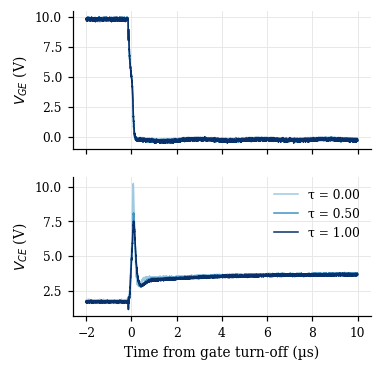

In [32]:
ton_final = FEAT["ton_us"].iloc[-100:].median()
bad = (FEAT["ton_us"] - ton_final).abs() > 0.2
K0 = int(FEAT.index[bad].max() + 1) if bad.any() else int(FEAT.index.min())
K0 += CFG.extra_burnin
KEOL = int(FEAT.index.max())
D = FEAT.loc[K0:KEOL].copy()
D["tau"] = (D.index - K0) / (KEOL - K0)
N_LIFE = KEOL - K0
print(f"Burn-in: captures {FEAT.index.min()}–{K0 - 1} removed ({K0 - FEAT.index.min()} captures). "
      f"Aging regime: {len(D)} captures, k0={K0}, EOL={KEOL}.")

# Figure 1: turn-off waveforms early / mid / late (sequential hue = aging order)
sel = [K0, K0 + (KEOL - K0) // 2, KEOL]
blues = ["#9ecae1", "#4292c6", "#08306b"]
fig, ax = plt.subplots(2, 1, figsize=(3.5, 3.6), sharex=True)
for c, k in zip(blues, sel):
    vg, vce, dt = WAVES[k]
    koff = np.where(vg > 5)[0][-1]
    t_us = (np.arange(len(vce)) - koff) * dt * 1e6
    m = (t_us > -2) & (t_us < 10)
    ax[0].plot(t_us[m], vg[m], color=c, lw=1.0)
    ax[1].plot(t_us[m], vce[m], color=c, lw=1.0, label=f"τ = {(k - K0) / (KEOL - K0):.2f}")
ax[0].set_ylabel("$V_{GE}$ (V)"); ax[1].set_ylabel("$V_{CE}$ (V)")
ax[1].set_xlabel("Time from gate turn-off (µs)"); ax[1].legend(frameon=False)
savefig(fig, "fig1_turnoff_waveforms")

## 7. Health-indicator selection
Standard PHM criteria are computed on the aging regime (Coble & Hines, 2009; Zhang et al., 2016):

* **Monotonicity** $=\left|\#(\Delta x>0)-\#(\Delta x<0)\right|/(n-1)$ on a centred moving median (window 15)
* **Trendability** $=|\rho_{\text{Spearman}}(x,\tau)|$
* **Robustness** $=\frac1n\sum \exp\left(-\left|(x-\tilde x)/x\right|\right)$, with $\tilde x$ the smoothed trend

Composite score = mean of the three. HI values are normalised to their first `norm_n` post-burn-in values (uses early data only, so there is no leakage).

Selected HI: os_area_norm


,monotonicity,trendability,robustness,SNR_dB,composite
os_area_norm,0.132,0.923,0.985,8.961,0.680
os_area,0.127,0.891,0.981,8.021,0.666
os_peak_norm,0.100,0.851,0.963,6.790,0.638
os_peak,0.095,0.834,0.959,5.649,0.629
vce_on,0.080,0.443,0.997,4.804,0.506
vce_off,0.042,0.093,0.995,-3.663,0.377


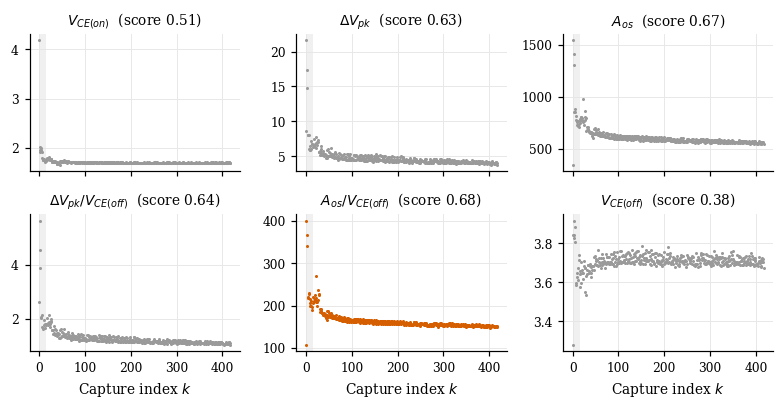

In [33]:
CANDIDATES = ["vce_on", "os_peak", "os_area", "os_peak_norm", "os_area_norm", "vce_off"]
LABELS = {"vce_on": "$V_{CE(on)}$", "os_peak": r"$\Delta V_{pk}$", "os_area": "$A_{os}$",
          "os_peak_norm": r"$\Delta V_{pk}/V_{CE(off)}$", "os_area_norm": r"$A_{os}/V_{CE(off)}$",
          "vce_off": "$V_{CE(off)}$"}

def hi_metrics(x, tau, w):
    s = pd.Series(x).rolling(w, center=True, min_periods=1).median().values
    d = np.diff(s)
    mon = abs((d > 0).sum() - (d < 0).sum()) / (len(x) - 1)
    tre = abs(spearmanr(x, tau).correlation)
    rob = np.mean(np.exp(-np.abs((x - s) / x)))
    snr = 10 * np.log10(np.var(s) / np.var(x - s))
    return dict(monotonicity=mon, trendability=tre, robustness=rob, SNR_dB=snr,
                composite=(mon + tre + rob) / 3)

HI_TAB = pd.DataFrame({c: hi_metrics(D[c].values, D["tau"].values, CFG.smooth_window)
                       for c in CANDIDATES}).T.sort_values("composite", ascending=False)
HI_NAME = HI_TAB.index[0] if CFG.hi_name == "auto" else CFG.hi_name
print("Selected HI:", HI_NAME)
display(HI_TAB.round(3))

# normalised HI
for c in CANDIDATES:
    D[c + "_n"] = D[c] / D[c].iloc[:CFG.norm_n].median()
TAU = D["tau"].values
Y = D[HI_NAME + "_n"].values

# Figure 2: candidate HIs (small multiples)
fig, axs = plt.subplots(2, 3, figsize=(7.2, 3.8), sharex=True)
for ax, c in zip(axs.ravel(), CANDIDATES):
    ax.axvspan(FEAT.index.min(), K0, color="#f0f0f0", lw=0)
    ax.plot(FEAT.index, FEAT[c], ".", ms=2, color=DATA_COLOR if c != HI_NAME else "#D55E00")
    ax.set_title(f"{LABELS[c]}  (score {HI_TAB.loc[c, 'composite']:.2f})")
for ax in axs[1]:
    ax.set_xlabel("Capture index $k$")
fig.tight_layout()
savefig(fig, "fig2_candidate_HIs")

## 8. Utilities: equation parser, refitting, physics check, metrics
PySR equation strings are parsed into a numeric template in which **every constant becomes a free parameter**. This allows (i) constants to be refitted on the full training window after structure selection and (ii) bootstrap uncertainty. A self-check compares the parser with `model.predict` for every equation.

In [34]:
_NUM = re.compile(r"(?<![A-Za-z_0-9.\]])((?:\d+\.\d*|\.\d+|\d+)(?:[eE][+-]?\d+)?)")
_SAFE = {"exp": np.exp, "log": np.log, "sqrt": np.sqrt, "square": np.square,
         "cube": lambda x: x ** 3, "abs": np.abs, "sin": np.sin, "cos": np.cos,
         "tanh": np.tanh, "neg": np.negative, "inv": lambda x: 1.0 / x}

class Expr:
    """PySR equation string → callable f(t, p) with all constants as parameters."""
    def __init__(self, eq, var="t"):
        self.eq, self.var = str(eq), var
        consts = []
        def rep(m):
            consts.append(float(m.group(1)))
            return f"p[{len(consts) - 1}]"
        self.template = _NUM.sub(rep, self.eq.replace("^", "**"))
        self.p0 = np.array(consts, float)
        self.form = _NUM.sub("C", self.eq).replace(" ", "")
        self.code = compile(self.template, "<expr>", "eval")

    def __call__(self, t, p=None):
        t = np.asarray(t, float)
        p = self.p0 if p is None else np.asarray(p, float)
        with np.errstate(all="ignore"):
            try:
                out = eval(self.code, {"__builtins__": {}, **_SAFE}, {self.var: t, "p": p})
            except Exception:
                return np.full_like(t, np.nan)
        return np.broadcast_to(np.asarray(out, float), t.shape).astype(float)

def refit(fun, p0, t, y):
    p0 = np.asarray(p0, float)
    if p0.size == 0:
        return p0
    def res(p):
        r = fun(t, p) - y
        return np.where(np.isfinite(r), r, 1e3)
    base = np.sum(res(p0) ** 2)
    try:
        sol = least_squares(res, p0, method="trf", x_scale="jac", max_nfev=3000)
        return sol.x if np.sum(res(sol.x) ** 2) <= base else p0
    except Exception:
        return p0

def admissible(fun, p, direction, y_ref, grid_max):
    g = np.linspace(0, grid_max, 400)
    v = fun(g, p)
    if not np.all(np.isfinite(v)) or np.max(np.abs(v)) > 10 * np.max(np.abs(y_ref)):
        return False
    d = np.diff(v)
    tol = 1e-9 * np.max(np.abs(v))
    return bool(np.all(d <= tol)) if direction < 0 else bool(np.all(d >= -tol))

def rmse(a, b): return float(np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2)))
def mae(a, b):  return float(np.mean(np.abs(np.asarray(a) - np.asarray(b))))
def r2(y, yh):  return float(1 - np.sum((y - yh) ** 2) / np.sum((y - np.mean(y)) ** 2))
def aic(y, yh, k):
    n = len(y); sse = np.sum((y - yh) ** 2)
    return float(n * np.log(sse / n) + 2 * k)

def bic(y, yh, k):
    n = len(y); sse = np.sum((y - yh) ** 2)
    return float(n * np.log(sse / n) + k * np.log(n))

# Functional families. An equation belongs to a family if that family reproduces its curve on τ ∈ [0, 1.2]
# to within family_tol × (curve range). This groups algebraically different strings of the same law,
# e.g. C/(t+C)+C, (-C/(-C-t))+C and (t*-C)/(t+C)+C are all hyperbolic.
FAMILIES = [  # simplest first; first match wins
    ("Hyperbolic c+a/(τ+b)", lambda t, p: p[0] + p[1] / (t + p[2]),
     [[0.7, 0.02, 0.05], [1.0, -0.3, 0.5], [0.5, 0.1, 0.2]]),
    ("Exponential c+a·exp(−kτ)", lambda t, p: p[0] + p[1] * np.exp(-p[2] * t),
     [[0.7, 0.3, 15.0], [0.8, 0.2, 3.0], [1.0, -0.2, 1.0]]),
    ("Power law c+a·τ^n", lambda t, p: p[0] + p[1] * np.power(t + 1e-3, p[2]),
     [[0.7, 0.1, -0.3], [1.0, -0.3, 0.5]]),
    ("Logarithmic c+a·ln(1+kτ)", lambda t, p: p[0] + p[1] * np.log1p(np.abs(p[2]) * t),
     [[1.0, -0.05, 50.0], [1.0, -0.1, 5.0]]),
    ("Exp.+linear c+a·exp(−kτ)+dτ", lambda t, p: p[0] + p[1] * np.exp(-p[2] * t) + p[3] * t,
     [[0.78, 0.29, 19.0, -0.09], [0.8, 0.2, 5.0, -0.05]]),
    ("Double exponential", lambda t, p: p[0] * np.exp(p[1] * t) + p[2] * np.exp(p[3] * t),
     [[0.3, -18.0, 0.78, -0.12], [0.5, -5.0, 0.5, -0.5]]),
]
FAMILY_GRID = np.linspace(0, 1.2, 400)

def classify_family(fun, p):
    y = fun(FAMILY_GRID, p)
    if not np.all(np.isfinite(y)):
        return "Other", None
    scale = max(np.ptp(y), 1e-9)
    for name, f, starts in FAMILIES:
        for p0 in starts:
            try:
                r = least_squares(lambda q: np.nan_to_num(f(FAMILY_GRID, q) - y, nan=1e3, posinf=1e3, neginf=-1e3),
                                  p0, max_nfev=5000)
            except Exception:
                continue
            if np.max(np.abs(f(FAMILY_GRID, r.x) - y)) < CFG.family_tol * scale:
                return name, r.x
    return "Other", None

def time_split(tau, tp, val_frac):
    tr = tau <= tp
    idx = np.where(tr)[0]
    n_val = max(5, int(round(val_frac * idx.size)))
    inner, val = idx[:-n_val], idx[-n_val:]
    return tr, ~tr, inner, val

## 9. Baselines
Classical empirical degradation models used in electronics prognostics, fitted by multi-start nonlinear least squares, plus a Gaussian-process regressor (RBF + linear + white-noise kernel, hyper-parameters by marginal likelihood). All baselines see exactly the same training window as SR.

In [35]:
BASELINES = {
    "Linear":       (lambda t, p: p[0] + p[1] * t, 2),
    "Quadratic":    (lambda t, p: p[0] + p[1] * t + p[2] * t ** 2, 3),
    "Exponential":  (lambda t, p: p[0] + p[1] * np.exp(p[2] * t), 3),
    "Power law":    (lambda t, p: p[0] + p[1] * np.power(t + 1e-3, p[2]), 3),
    "Logarithmic":  (lambda t, p: p[0] + p[1] * np.log1p(np.abs(p[2]) * t), 3),
    "Double exp.":  (lambda t, p: p[0] * np.exp(p[1] * t) + p[2] * np.exp(p[3] * t), 4),
}

def fit_baseline(name, t, y, n_starts=40, seed=0):
    fun, k = BASELINES[name]
    rng = np.random.default_rng(seed)
    best, best_sse = None, np.inf
    for _ in range(n_starts):
        p0 = rng.normal(0, 1, k) * np.r_[np.mean(y), np.ones(k - 1)] if k > 1 else [np.mean(y)]
        p0[0] = np.mean(y) if name != "Double exp." else p0[0]
        p = refit(fun, p0, t, y)
        sse = np.sum((fun(t, p) - y) ** 2)
        if np.isfinite(sse) and sse < best_sse:
            best, best_sse = p, sse
    return fun, best

def fit_gpr(t, y, seed=0):
    kern = (ConstantKernel(1.0) * RBF(0.3, (1e-2, 1e2)) + ConstantKernel(0.1) * DotProduct(0.1)
            + WhiteKernel(1e-4, (1e-8, 1e0)))
    g = GaussianProcessRegressor(kern, normalize_y=True, n_restarts_optimizer=5, random_state=seed)
    g.fit(t[:, None], y)
    return g

## 10. Symbolic regression runs (τp × seeds), with caching
PySR is run in deterministic, serial mode for exact reproducibility. For each prediction point:

1. PySR is fitted on the **inner** training window (first 85 % of the data up to τp).
2. Every Pareto-front equation is scored on the **validation** window (last 15 % before τp).
3. **Proposed selection:** among physics-admissible equations, take the simplest one whose validation RMSE is within 5 % of the best. Refit its constants on the whole training window.
4. **Ablations:** (a) same without the physics filter; (b) PySR's built-in `model_selection="best"` choice, constants from PySR.

In [36]:
def run_pysr(t_fit, y_fit, seed, tag):
    cache = OUT / "sr_cache" / f"{tag}.csv"
    if cache.exists():
        return pd.read_csv(cache)
    model = PySRRegressor(
        niterations=CFG.niterations, populations=CFG.populations,
        population_size=CFG.population_size, maxsize=CFG.maxsize, maxdepth=CFG.maxdepth,
        binary_operators=list(CFG.binary_operators), unary_operators=list(CFG.unary_operators),
        nested_constraints={"exp": {"exp": 0, "log": 0}, "log": {"exp": 0, "log": 0},
                            "sqrt": {"sqrt": 0}},
        model_selection="best", precision=64,
        deterministic=True, parallelism="serial", random_state=seed,
        progress=False, verbosity=0,
        output_directory=str(OUT / "pysr_runs"), run_id=tag,
    )
    X = pd.DataFrame({"t": t_fit})
    model.fit(X, y_fit)
    eqs = model.equations_.reset_index(drop=True)
    out = eqs[["complexity", "loss", "equation"]].copy()
    out["score"] = eqs["score"] if "score" in eqs else np.nan
    best_idx = int(model.equations_.index.get_loc(model.get_best().name))
    out["pysr_best"] = False
    out.loc[best_idx, "pysr_best"] = True
    ok, latex = [], []
    for i in range(len(out)):
        e = Expr(out.loc[i, "equation"])
        yp = np.asarray(model.predict(X, index=i), float)
        ye = e(t_fit)
        ok.append(bool(np.all(np.isfinite(ye))) and np.nanmax(np.abs(ye - yp)) <= 1e-6 * (1 + np.nanmax(np.abs(yp))))
        try:
            latex.append(model.latex(index=i, precision=4))
        except Exception:
            latex.append("")
    out["parse_ok"], out["latex"] = ok, latex
    out.to_csv(cache, index=False)
    return out

def select_equation(eqs, t_in, y_in, t_val, y_val, t_tr, y_tr, direction, physics=True):
    cands = []
    for _, r in eqs.iterrows():
        if not r["parse_ok"]:
            continue
        e = Expr(r["equation"])
        yv = e(t_val)
        if not np.all(np.isfinite(yv)):
            continue
        adm = admissible(e, e.p0, direction, y_tr, CFG.admissible_grid_max)
        cands.append(dict(eq=r["equation"], complexity=int(r["complexity"]), val_rmse=rmse(y_val, yv),
                          admissible=adm, n_params=e.p0.size))
    C = pd.DataFrame(cands)
    if physics:
        C = C[C["admissible"]]
    if C.empty:
        return None
    best = C["val_rmse"].min()
    pick = C[C["val_rmse"] <= best * (1 + CFG.tie_tolerance)].sort_values("complexity").iloc[0]
    e = Expr(pick["eq"])
    p = refit(e, e.p0, t_tr, y_tr)
    if physics and not admissible(e, p, direction, y_tr, CFG.admissible_grid_max):
        p = e.p0  # keep PySR constants if the refit breaks admissibility
    return dict(expr=e, p=p, complexity=int(pick["complexity"]), val_rmse=float(pick["val_rmse"]),
                n_admissible=int(len(C)))

def select_bic(eqs, t_tr, y_tr, direction):
    """Post-hoc variant: refit every admissible Pareto equation on the training window, pick minimum BIC."""
    best = None
    for _, r in eqs.iterrows():
        if not r["parse_ok"]:
            continue
        e = Expr(r["equation"])
        p = refit(e, e.p0, t_tr, y_tr)
        yh = e(t_tr, p)
        if not np.all(np.isfinite(yh)) or not admissible(e, p, direction, y_tr, CFG.admissible_grid_max):
            continue
        b = bic(y_tr, yh, p.size)
        if best is None or b < best["bic"]:
            best = dict(expr=e, p=p, complexity=int(r["complexity"]), val_rmse=np.nan, n_admissible=np.nan, bic=b)
    return best

SR_ROWS, SR_MODELS = [], {}
t_start = time.time()
for tp in CFG.pred_points:
    tr, te, inner, val = time_split(TAU, tp, CFG.inner_val_frac)
    direction = np.sign(spearmanr(TAU[tr], Y[tr]).correlation)
    for seed in CFG.seeds:
        tag = f"{HI_NAME}_tp{int(tp * 100)}_s{seed}_it{CFG.niterations}"
        eqs = run_pysr(TAU[inner], Y[inner], seed, tag)
        variants = {
            "proposed": select_equation(eqs, TAU[inner], Y[inner], TAU[val], Y[val], TAU[tr], Y[tr], direction, True),
            "no_physics": select_equation(eqs, TAU[inner], Y[inner], TAU[val], Y[val], TAU[tr], Y[tr], direction, False),
        }
        rb = eqs[eqs["pysr_best"]].iloc[0]
        eb = Expr(rb["equation"])
        variants["pysr_default"] = dict(expr=eb, p=eb.p0, complexity=int(rb["complexity"]), val_rmse=np.nan, n_admissible=np.nan)
        variants["bic_posthoc"] = select_bic(eqs, TAU[tr], Y[tr], direction)
        for vname, s in variants.items():
            if s is None:
                continue
            yh_tr, yh_te = s["expr"](TAU[tr], s["p"]), s["expr"](TAU[te], s["p"])
            fam, fam_p = classify_family(s["expr"], s["p"])
            s["family"], s["family_params"] = fam, fam_p
            SR_MODELS[(tp, seed, vname)] = s
            SR_ROWS.append(dict(tp=tp, seed=seed, variant=vname, family=fam, equation=s["expr"].eq, form=s["expr"].form,
                                refit_params=np.round(s["p"], 6).tolist(), complexity=s["complexity"],
                                n_params=s["p"].size, n_admissible=s["n_admissible"], val_rmse=s["val_rmse"],
                                train_rmse=rmse(Y[tr], yh_tr), test_rmse=rmse(Y[te], yh_te),
                                test_mae=mae(Y[te], yh_te), test_r2=r2(Y[te], yh_te),
                                aic_train=aic(Y[tr], yh_tr, s["p"].size), bic_train=bic(Y[tr], yh_tr, s["p"].size),
                                admissible=admissible(s["expr"], s["p"], direction, Y[tr], CFG.admissible_grid_max)))
        print(f"τp={tp:.1f} seed={seed}: [{variants['proposed']['family'] if variants['proposed'] else '—'}] "
              f"{variants['proposed']['expr'].eq if variants['proposed'] else '—'}"
              f"   [{time.time() - t_start:.0f} s]")
SR = pd.DataFrame(SR_ROWS)
SR.to_csv(OUT / "tables" / "sr_all_runs.csv", index=False)

τp=0.5 seed=0: [Exponential c+a·exp(−kτ)] (exp(t * -16.179917559666244) * 0.3124758015793966) + 0.7483304879596716   [30 s]
τp=0.5 seed=1: [Hyperbolic c+a/(τ+b)] (t * (-0.37609543653675453 / (t + 0.048417261515594716))) + 1.0721440541546896   [34 s]
τp=0.5 seed=2: [Hyperbolic c+a/(τ+b)] (0.018617543451437808 / (t + 0.049660444841463376)) + 0.6952406586182662   [34 s]
τp=0.5 seed=3: [Other] sqrt(exp(t / (-0.06856385191614604 - t)) + 0.11809966778499847)   [47 s]
τp=0.5 seed=4: [Hyperbolic c+a/(τ+b)] ((t * -0.37609545972296404) / (t + 0.04841725103202985)) + 1.0721440842589884   [58 s]
τp=0.6 seed=0: [Exponential c+a·exp(−kτ)] 0.7440302462294145 + (exp(t / -0.0652027814670436) * 0.3128497984947064)   [59 s]
τp=0.6 seed=1: [Hyperbolic c+a/(τ+b)] (0.01774351937786396 / (t + 0.047338777805095704)) + 0.6982101518092594   [59 s]
τp=0.6 seed=2: [Hyperbolic c+a/(τ+b)] ((t + 0.07275170077745674) * 0.6982101152541903) / (t + 0.04733881730628756)   [67 s]
τp=0.6 seed=3: [Hyperbolic c+a/(τ+b)] 0.69

In [37]:
# ---------------------------------------------------------------- 11. Baseline fits
BL_ROWS, BL_MODELS = [], {}
for tp in CFG.pred_points:
    tr, te, _, _ = time_split(TAU, tp, CFG.inner_val_frac)
    for name in BASELINES:
        fun, p = fit_baseline(name, TAU[tr], Y[tr], seed=CFG.random_state)
        yh_tr, yh_te = fun(TAU[tr], p), fun(TAU[te], p)
        BL_MODELS[(tp, name)] = (fun, p)
        BL_ROWS.append(dict(tp=tp, method=name, n_params=len(p), train_rmse=rmse(Y[tr], yh_tr),
                            test_rmse=rmse(Y[te], yh_te), test_mae=mae(Y[te], yh_te),
                            test_r2=r2(Y[te], yh_te), aic_train=aic(Y[tr], yh_tr, len(p)),
                            bic_train=bic(Y[tr], yh_tr, len(p))))
    g = fit_gpr(TAU[tr], Y[tr], CFG.random_state)
    BL_MODELS[(tp, "GPR")] = g
    yh_tr, yh_te = g.predict(TAU[tr][:, None]), g.predict(TAU[te][:, None])
    BL_ROWS.append(dict(tp=tp, method="GPR", n_params=np.nan, train_rmse=rmse(Y[tr], yh_tr),
                        test_rmse=rmse(Y[te], yh_te), test_mae=mae(Y[te], yh_te),
                        test_r2=r2(Y[te], yh_te), aic_train=np.nan, bic_train=np.nan))
BL = pd.DataFrame(BL_ROWS)
BL.to_csv(OUT / "tables" / "baselines.csv", index=False)

## 12. Main results: extrapolation accuracy
SR is reported as mean ± s.d. over seeds. "Win rate" is the fraction of seeds in which SR beats the **best** baseline at that τp (an oracle choice that favours the baselines).
"SR-BIC" is the **post-hoc** variant (minimum BIC on the training window). It was added after the first run showed that the pre-registered rule favours the simplest law; report it as a secondary analysis, not as the main method.

In [38]:
def fmt(m, s):
    return f"{m:.4f} ± {s:.4f}" if np.isfinite(s) else f"{m:.4f}"

prop = SR[SR.variant == "proposed"]
bicv = SR[SR.variant == "bic_posthoc"]
summary = []
for tp in CFG.pred_points:
    p_ = prop[prop.tp == tp]
    b_ = BL[BL.tp == tp].set_index("method")
    best_bl = b_["test_rmse"].idxmin()
    row = {"τp": tp, "SR test RMSE": fmt(p_.test_rmse.mean(), p_.test_rmse.std(ddof=1)),
           "SR test MAE": fmt(p_.test_mae.mean(), p_.test_mae.std(ddof=1)),
           "SR complexity": fmt(p_.complexity.mean(), p_.complexity.std(ddof=1))}
    for m in b_.index:
        row[f"{m} RMSE"] = f"{b_.loc[m, 'test_rmse']:.4f}"
    row["best baseline"] = best_bl
    row["SR win rate"] = f"{(p_.test_rmse < b_.loc[best_bl, 'test_rmse']).mean():.2f}"
    q_ = bicv[bicv.tp == tp]
    if len(q_):
        row["SR-BIC test RMSE (post hoc)"] = fmt(q_.test_rmse.mean(), q_.test_rmse.std(ddof=1))
        row["SR-BIC win rate (post hoc)"] = f"{(q_.test_rmse < b_.loc[best_bl, 'test_rmse']).mean():.2f}"
    summary.append(row)
T_MAIN = pd.DataFrame(summary)
T_MAIN.to_csv(OUT / "tables" / "table_main_results.csv", index=False)
T_MAIN.T

,0,1,2,3
τp,0.5,0.6,0.7,0.8
SR test RMSE,0.0179 ± 0.0091,0.0206 ± 0.0096,0.0122 ± 0.0014,0.0125 ± 0.0019
SR test MAE,0.0156 ± 0.0089,0.0184 ± 0.0094,0.0102 ± 0.0014,0.0104 ± 0.0017
SR complexity,8.4000 ± 0.8944,8.2000 ± 0.8367,9.0000 ± 2.7386,8.0000 ± 2.2361
Linear RMSE,0.1258,0.0906,0.0673,0.0502
Quadratic RMSE,0.4160,0.2247,0.1304,0.0799
Exponential RMSE,0.0342,0.0312,0.0287,0.0273
Power law RMSE,0.0268,0.0201,0.0158,0.0120
Logarithmic RMSE,0.0297,0.0240,0.0198,0.0159
Double exp. RMSE,0.0106,0.0106,0.0102,0.0089


In [39]:
ABL = (SR.groupby(["tp", "variant"])
         .agg(test_rmse_mean=("test_rmse", "mean"), test_rmse_sd=("test_rmse", "std"),
              complexity=("complexity", "mean"), n_params=("n_params", "mean"),
              admissible_rate=("admissible", "mean"),
              main_family=("family", lambda v: v.value_counts().index[0]),
              main_family_share=("family", lambda v: v.value_counts().iloc[0] / len(v)))
         .reset_index())
ABL.to_csv(OUT / "tables" / "table_ablation.csv", index=False)
display(ABL.round(4))

# Information criteria on the training window (lower = better; ΔBIC > 10 is "very strong" evidence)
IC = []
for tp in CFG.pred_points:
    for v, lab in (("proposed", "SR (proposed)"), ("bic_posthoc", "SR-BIC (post hoc)")):
        q_ = SR[(SR.tp == tp) & (SR.variant == v)]
        IC.append(dict(tp=tp, model=lab, k=q_.n_params.median(), BIC=q_.bic_train.median(), test_rmse=q_.test_rmse.median()))
    for _, r_ in BL[(BL.tp == tp) & (BL.method != "GPR")].iterrows():
        IC.append(dict(tp=tp, model=r_.method, k=r_.n_params, BIC=r_.bic_train, test_rmse=r_.test_rmse))
T_IC = pd.DataFrame(IC)
T_IC["ΔBIC vs best"] = T_IC.BIC - T_IC.groupby("tp").BIC.transform("min")
T_IC = T_IC.sort_values(["tp", "BIC"])
T_IC.to_csv(OUT / "tables" / "table_information_criteria.csv", index=False)
T_IC.round(4)

,tp,variant,test_rmse_mean,test_rmse_sd,complexity,n_params,admissible_rate,main_family,main_family_share
0,0.5,bic_posthoc,0.0175,0.0082,10.4,3.0,1.0,Other,0.8
1,0.5,no_physics,0.0515,0.0824,9.2,2.4,0.6,Other,0.4
2,0.5,proposed,0.0179,0.0091,8.4,2.8,1.0,Hyperbolic c+a/(τ+b),0.6
3,0.5,pysr_default,0.1179,0.1330,9.8,2.8,0.4,Other,0.6
4,0.6,bic_posthoc,0.0278,0.0080,10.0,3.2,1.0,Other,0.6
5,0.6,no_physics,0.0204,0.0092,9.6,3.4,0.8,Hyperbolic c+a/(τ+b),0.6
6,0.6,proposed,0.0206,0.0096,8.2,3.2,1.0,Hyperbolic c+a/(τ+b),0.6
7,0.6,pysr_default,0.0461,0.0439,7.6,2.8,0.8,Exponential c+a·exp(−kτ),0.4
8,0.7,bic_posthoc,0.0215,0.0054,13.4,3.8,1.0,Other,1.0
9,0.7,no_physics,0.0122,0.0014,9.0,3.4,1.0,Hyperbolic c+a/(τ+b),0.6


,tp,model,k,BIC,test_rmse,ΔBIC vs best
4,0.5,Exponential,3.0,-1368.1146,0.0342,0.0000
7,0.5,Double exp.,4.0,-1367.3432,0.0106,0.7714
1,0.5,SR-BIC (post hoc),3.0,-1356.8825,0.0138,11.2321
0,0.5,SR (proposed),3.0,-1356.5214,0.0137,11.5932
6,0.5,Logarithmic,3.0,-1309.0721,0.0297,59.0424
5,0.5,Power law,3.0,-1296.6570,0.0268,71.4576
3,0.5,Quadratic,3.0,-1272.3628,0.4160,95.7517
2,0.5,Linear,2.0,-1168.3231,0.1258,199.7915
15,0.6,Double exp.,4.0,-1678.8129,0.0106,0.0000
9,0.6,SR-BIC (post hoc),3.0,-1669.1058,0.0309,9.7071


## 13. Discovered equations and their stability across seeds
PySR often writes the same law in different ways (`C/(t+C)+C`, `(-C/(-C-t))+C`, `(t*-C)/(t+C)+C`, … are all the same hyperbola). Comparing strings therefore **undercounts** agreement between seeds. Each selected equation is instead assigned to a *functional family* (Section 8): the family that reproduces its curve on τ ∈ [0, 1.2] to within 0.1 % of the curve range. A family found by many seeds, and at several prediction points, with stable constants, is strong evidence of a real degradation law.

**Reading the hyperbolic law.** $HI(\tau) = c + a/(\tau+b)$ is the solution of $dHI/d\tau = -(HI-c)^2/a$: a second-order relaxation towards a floor $c$. In the exponential law the decay rate is proportional to the remaining distance to the floor (first-order). In the hyperbolic law it is proportional to the square of that distance, so the approach to the floor slows down much more (heavy tail).

In [40]:
FAMILY_PARAM_NAMES = {
    "Hyperbolic c+a/(τ+b)": ["c", "a", "b"], "Exponential c+a·exp(−kτ)": ["c", "a", "k"],
    "Power law c+a·τ^n": ["c", "a", "n"], "Logarithmic c+a·ln(1+kτ)": ["c", "a", "k"],
    "Exp.+linear c+a·exp(−kτ)+dτ": ["c", "a", "k", "d"], "Double exponential": ["a1", "k1", "a2", "k2"],
}
# (a) family counts per variant — the main stability result
FAM_TAB = (SR[SR.variant.isin(["proposed", "bic_posthoc"])]
           .groupby(["variant", "family"])
           .agg(n_runs=("seed", "size"), n_tp=("tp", "nunique"), median_test_rmse=("test_rmse", "median"),
                median_params=("n_params", "median"))
           .reset_index().sort_values(["variant", "n_runs"], ascending=[False, False]))
FAM_TAB["share"] = FAM_TAB.n_runs / FAM_TAB.groupby("variant").n_runs.transform("sum")
FAM_TAB.to_csv(OUT / "tables" / "table_family_stability.csv", index=False)
print("Functional families of the selected equations (all τp × seeds):")
display(FAM_TAB.round(4))
print("\nFamily per prediction point (proposed rule):")
display(pd.crosstab(prop.tp, prop.family))

# (b) constants of the dominant family across seeds and prediction points
DOM_FAMILY = prop.family.value_counts().index[0]
cons = []
for (tp, seed, v), s_ in SR_MODELS.items():
    if v == "proposed" and s_["family"] == DOM_FAMILY and s_["family_params"] is not None:
        cons.append(dict(tp=tp, seed=seed, **dict(zip(FAMILY_PARAM_NAMES.get(DOM_FAMILY, []), s_["family_params"]))))
T_CONST = pd.DataFrame(cons)
if len(T_CONST):
    T_CONST_SUM = T_CONST.drop(columns="seed").groupby("tp").agg(["mean", "std", "count"])
    T_CONST_SUM.to_csv(OUT / "tables" / "table_dominant_family_constants.csv")
    print(f"\nConstants of the dominant family ({DOM_FAMILY}):")
    display(T_CONST_SUM.round(4))

# (c) string-level forms (kept for transparency; undercounts equivalent laws)
STAB = (prop.groupby(["tp", "form"]).agg(n_seeds=("seed", "size"), family=("family", "first"),
                                         median_test_rmse=("test_rmse", "median"),
                                         example=("equation", "first")).reset_index()
        .sort_values(["tp", "n_seeds"], ascending=[True, False]))
STAB.to_csv(OUT / "tables" / "table_equation_strings.csv", index=False)
GLOBAL_FAMILIES = prop.groupby("family").agg(n_runs=("seed", "size"), n_tp=("tp", "nunique"),
                                             median_test_rmse=("test_rmse", "median")).sort_values("n_runs", ascending=False)

Functional families of the selected equations (all τp × seeds):


,variant,family,n_runs,n_tp,median_test_rmse,median_params,share
5,proposed,Hyperbolic c+a/(τ+b),13,4,0.0133,3.0,0.65
3,proposed,Exp.+linear c+a·exp(−kτ)+dτ,3,2,0.0107,4.0,0.15
4,proposed,Exponential c+a·exp(−kτ),3,2,0.0312,3.0,0.15
6,proposed,Other,1,1,0.0141,2.0,0.05
2,bic_posthoc,Other,17,4,0.0195,3.0,0.85
1,bic_posthoc,Hyperbolic c+a/(τ+b),2,2,0.0137,3.0,0.10
0,bic_posthoc,Exponential c+a·exp(−kτ),1,1,0.0312,3.0,0.05



Family per prediction point (proposed rule):


family,Exp.+linear c+a·exp(−kτ)+dτ,Exponential c+a·exp(−kτ),Hyperbolic c+a/(τ+b),Other
tp,,,,
0.5,0,1,3,1
0.6,0,2,3,0
0.7,2,0,3,0
0.8,1,0,4,0



Constants of the dominant family (Hyperbolic c+a/(τ+b)):


c                  a                  b           
       mean  std count    mean  std count    mean  std count
tp                                                          
0.5  0.6982  0.0     3  0.0177  0.0     3  0.0473  0.0     3
0.6  0.6971  0.0     3  0.0180  0.0     3  0.0479  0.0     3
0.7  0.6955  0.0     3  0.0184  0.0     3  0.0489  0.0     3
0.8  0.6940  0.0     4  0.0188  0.0     4  0.0499  0.0     4

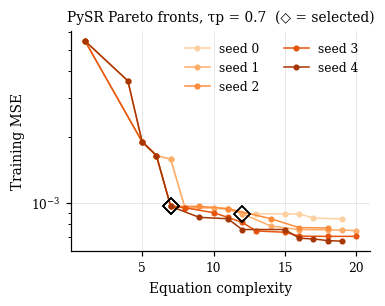

In [41]:
# Figure 3: Pareto fronts (training loss vs complexity) for τp = 0.7, all seeds
tp_show = 0.7 if 0.7 in CFG.pred_points else CFG.pred_points[-1]
fig, ax = plt.subplots(figsize=(3.5, 2.6))
seq = ["#fdd0a2", "#fdae6b", "#fd8d3c", "#e6550d", "#a63603"]
for i, seed in enumerate(CFG.seeds):
    eqs = pd.read_csv(OUT / "sr_cache" / f"{HI_NAME}_tp{int(tp_show * 100)}_s{seed}_it{CFG.niterations}.csv")
    ax.plot(eqs.complexity, eqs.loss, marker="o", ms=3, lw=1, color=seq[i % len(seq)], label=f"seed {seed}")
    ch = SR_MODELS[(tp_show, seed, "proposed")]["complexity"]
    ax.plot(ch, eqs.loc[eqs.complexity == ch, "loss"].values[0], marker="D", mfc="none", mec="k", ms=7, ls="none", zorder=5)
ax.set_yscale("log"); ax.set_xlabel("Equation complexity"); ax.set_ylabel("Training MSE")
ax.set_title(f"PySR Pareto fronts, τp = {tp_show}  (◇ = selected)")
ax.legend(frameon=False, ncol=2)
savefig(fig, "fig3_pareto_fronts")

## 14. Uncertainty: moving-block residual bootstrap
Residuals of a degradation trajectory are autocorrelated, so a moving-block bootstrap (block length ≈ n^{1/3}) is used. For each resample the constants of the selected SR form (and of the best parametric baseline) are refitted, and the forecast plus a resampled residual gives the predictive distribution. Reported: PICP (coverage of the 95 % interval on the test window, ideal ≈ 0.95) and MPIW (mean interval width, smaller is better).

In [42]:
def block_bootstrap(res, rng):
    n = len(res); L = max(2, int(round(n ** (1 / 3))))
    idx = []
    while len(idx) < n:
        s = rng.integers(0, n - L + 1)
        idx.extend(range(s, s + L))
    return res[np.array(idx[:n])]

def bootstrap_pi(fun, p_hat, t_tr, y_tr, t_eval, B, rng):
    yh = fun(t_tr, p_hat)
    res = y_tr - yh
    sims, params = [], []
    for _ in range(B):
        yb = yh + block_bootstrap(res, rng)
        pb = refit(fun, p_hat, t_tr, yb)
        f_eval = fun(t_eval, pb)
        if not np.all(np.isfinite(f_eval)):
            continue
        params.append(pb)
        sims.append(f_eval[None, :] + rng.choice(res, size=(20, t_eval.size), replace=True))
    sims = np.concatenate(sims, axis=0)
    a = (1 - CFG.pi_level) / 2
    return np.quantile(sims, a, axis=0), np.quantile(sims, 1 - a, axis=0), np.array(params)

rng = np.random.default_rng(CFG.random_state)
T_GRID = np.linspace(0, 1.05, 300)
UQ_ROWS, BANDS, BOOT_PARAMS = [], {}, {}
for tp in CFG.pred_points:
    tr, te, _, _ = time_split(TAU, tp, CFG.inner_val_frac)
    for seed in CFG.seeds:
        s = SR_MODELS[(tp, seed, "proposed")]
        lo, hi, P = bootstrap_pi(s["expr"], s["p"], TAU[tr], Y[tr], np.r_[TAU[te], T_GRID], CFG.n_bootstrap, rng)
        n_te = te.sum()
        BANDS[(tp, seed)] = (lo[n_te:], hi[n_te:]); BOOT_PARAMS[(tp, seed)] = P
        UQ_ROWS.append(dict(tp=tp, method="SR (proposed)", seed=seed,
                            PICP=float(np.mean((Y[te] >= lo[:n_te]) & (Y[te] <= hi[:n_te]))),
                            MPIW=float(np.mean(hi[:n_te] - lo[:n_te]))))
    best_bl = BL[(BL.tp == tp) & (BL.method != "GPR")].sort_values("test_rmse").iloc[0]["method"]
    fun, p = BL_MODELS[(tp, best_bl)]
    lo, hi, _ = bootstrap_pi(fun, p, TAU[tr], Y[tr], TAU[te], CFG.n_bootstrap, rng)
    UQ_ROWS.append(dict(tp=tp, method=best_bl, seed=np.nan,
                        PICP=float(np.mean((Y[te] >= lo) & (Y[te] <= hi))), MPIW=float(np.mean(hi - lo))))
    g = BL_MODELS[(tp, "GPR")]
    mu, sd = g.predict(TAU[te][:, None], return_std=True)
    z = 1.959964
    UQ_ROWS.append(dict(tp=tp, method="GPR", seed=np.nan,
                        PICP=float(np.mean(np.abs(Y[te] - mu) <= z * sd)), MPIW=float(np.mean(2 * z * sd))))
UQ = pd.DataFrame(UQ_ROWS)
T_UQ = UQ.groupby(["tp", "method"]).agg(PICP=("PICP", "mean"), MPIW=("MPIW", "mean")).reset_index()
T_UQ.to_csv(OUT / "tables" / "table_uncertainty.csv", index=False)
T_UQ.round(3)

,tp,method,PICP,MPIW
0,0.5,Double exp.,1.000,0.124
1,0.5,GPR,1.000,0.327
2,0.5,SR (proposed),0.996,0.091
3,0.6,Double exp.,1.000,0.092
4,0.6,GPR,1.000,0.283
5,0.6,SR (proposed),0.996,0.082
6,0.7,Double exp.,1.000,0.081
7,0.7,GPR,1.000,0.275
8,0.7,SR (proposed),1.000,0.076
9,0.8,Double exp.,1.000,0.074


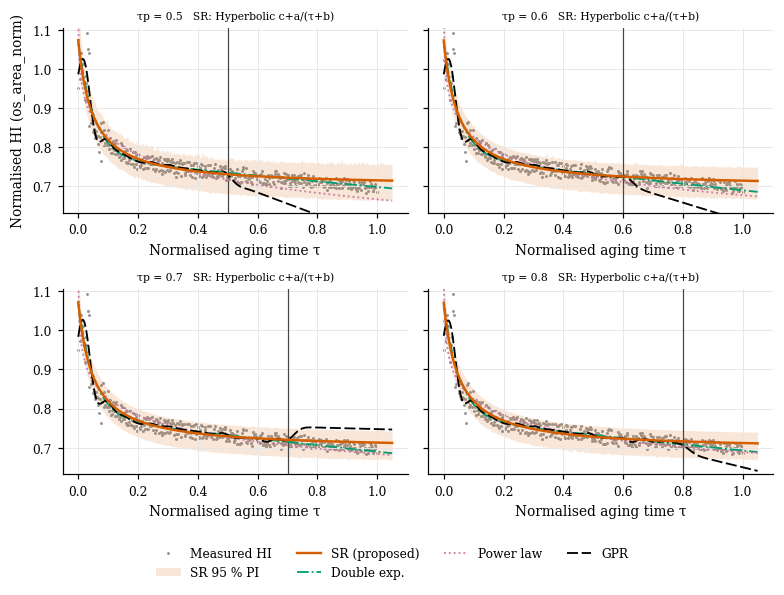

In [43]:
# Figure 4: forecasts at each prediction point (representative seed = median test RMSE)
def rep_seed(tp):
    p_ = prop[prop.tp == tp].sort_values("test_rmse")
    return int(p_.iloc[len(p_) // 2]["seed"])

n_tp = len(CFG.pred_points)
ncol = 2 if n_tp > 1 else 1
nrow = int(np.ceil(n_tp / ncol))
fig, axs = plt.subplots(nrow, ncol, figsize=(7.2, 2.6 * nrow), sharey=True, squeeze=False)
for ax, tp in zip(axs.ravel(), CFG.pred_points):
    tr, te, _, _ = time_split(TAU, tp, CFG.inner_val_frac)
    ax.plot(TAU, Y, ".", ms=2, color=DATA_COLOR, label="Measured HI", zorder=1)
    ax.axvline(tp, color="#444444", lw=0.8)
    sd_ = rep_seed(tp); s = SR_MODELS[(tp, sd_, "proposed")]
    lo, hi = BANDS[(tp, sd_)]
    ax.fill_between(T_GRID, lo, hi, color=STYLE["SR (proposed)"][0], alpha=0.15, lw=0, label="SR 95 % PI")
    ax.plot(T_GRID, s["expr"](T_GRID, s["p"]), color=STYLE["SR (proposed)"][0], ls="-", label="SR (proposed)", zorder=4)
    b_ = BL[BL.tp == tp].sort_values("test_rmse")
    shown = [m for m in b_.method if m != "GPR"][:2] + ["GPR"]
    for m in shown:
        c, ls = STYLE[m]
        if m == "GPR":
            yy = BL_MODELS[(tp, m)].predict(T_GRID[:, None])
        else:
            fun, p = BL_MODELS[(tp, m)]; yy = fun(T_GRID, p)
        ax.plot(T_GRID, yy, color=c, ls=ls, lw=1.2, label=m, zorder=3)
    ax.set_title(f"τp = {tp}   SR: {s['family']}", fontsize=7)
    ax.set_xlabel("Normalised aging time τ")
    lo_y, hi_y = np.percentile(Y, [0.5, 99.5]); pad = 0.15 * (hi_y - lo_y)
    ax.set_ylim(lo_y - pad, hi_y + pad)
axs[0, 0].set_ylabel(f"Normalised HI ({HI_NAME})")
for ax in axs.ravel()[n_tp:]:
    ax.axis("off")
h, l = axs[0, 0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.04))
fig.tight_layout(rect=(0, 0.06, 1, 1))
savefig(fig, "fig4_forecasts")

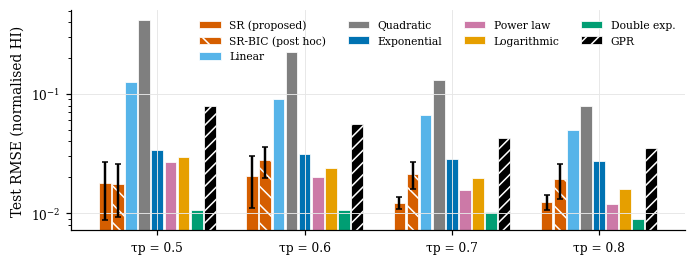

In [44]:
# Figure 5: test RMSE by method and prediction point (SR = mean ± s.d. over seeds)
methods = ["SR (proposed)", "SR-BIC (post hoc)"] + list(BASELINES) + ["GPR"]
fig, ax = plt.subplots(figsize=(7.2, 2.6))
w = 0.8 / len(methods)
for j, m in enumerate(methods):
    xs = np.arange(n_tp) + (j - len(methods) / 2 + 0.5) * w
    if m.startswith("SR"):
        g = (prop if m == "SR (proposed)" else bicv).groupby("tp").test_rmse
        ax.bar(xs, g.mean().values, w * 0.9, yerr=g.std(ddof=1).values, color=STYLE["SR (proposed)"][0], label=m,
               capsize=2, hatch=None if m == "SR (proposed)" else "\\\\", edgecolor="white", linewidth=0.5)
    else:
        v = BL[BL.method == m].set_index("tp").loc[list(CFG.pred_points), "test_rmse"].values
        ax.bar(xs, v, w * 0.9, color=STYLE[m][0], label=m, hatch="///" if m == "GPR" else None,
               edgecolor="white", linewidth=0.5)
ax.set_xticks(np.arange(n_tp)); ax.set_xticklabels([f"τp = {t}" for t in CFG.pred_points])
ax.set_yscale("log"); ax.set_ylabel("Test RMSE (normalised HI)")
ax.legend(frameon=False, ncol=4, fontsize=7)
savefig(fig, "fig5_test_rmse")

## 15. Long-horizon behaviour of the discovered laws (floor analysis)
The first full run showed that threshold-crossing RUL is **ill-posed** for this HI. The indicator saturates, and the most common discovered law (hyperbolic) has a floor $c$ that sits almost exactly at the level observed just before latch-up. A model that levels off at the threshold never "crosses" it, so RUL comes out censored or arbitrary.

This section therefore asks a better-posed question: **what does each law say about the HI beyond the observed data, and where does the device sit on that curve when it fails?**

* *Bounded* – the law levels off: $|HI(1000)-HI(100)| < 1\%$ of the drop over the observed life. *Floor* = $HI(\tau\to\infty)$ (evaluated at τ = 1000).
* *Completed at EOL* – $\dfrac{HI(0)-HI(1)}{HI(0)-HI(\infty)}$: the fraction of the law's total eventual decay that had already happened when the device latched up.
* The floor's 95 % interval for the proposed SR runs comes from the bootstrap parameter sets of Section 14.

If the floor lies at or just below the pre-failure HI level and "completed at EOL" is close to 1, the turn-off overshoot has **saturated before failure**: it tracks the degradation process but does not by itself signal the time of latch-up. That is a finding worth stating explicitly.

In [45]:
Y_EOL = float(np.mean(Y[-CFG.rul_threshold_window:]))
Y_EOL_BAND = (float(np.min(Y[-40:])), float(np.max(Y[-40:])))

def long_run(fun, p):
    v = np.asarray(fun(np.array([0.0, 1.0, 100.0, 1000.0]), p), float)
    if not np.all(np.isfinite(v)):
        return dict(bounded=False, floor=np.nan, completed_at_eol=np.nan)
    bounded = abs(v[3] - v[2]) < 0.01 * abs(v[0] - v[1])
    return dict(bounded=bool(bounded), floor=float(v[3]) if bounded else np.nan,
                completed_at_eol=float((v[0] - v[1]) / (v[0] - v[3])) if bounded and v[0] != v[3] else np.nan)

FL = []
for tp in CFG.pred_points:
    for seed in CFG.seeds:
        for v, lab in (("proposed", "SR (proposed)"), ("bic_posthoc", "SR-BIC (post hoc)")):
            s_ = SR_MODELS.get((tp, seed, v))
            if s_ is None:
                continue
            row = dict(tp=tp, seed=seed, model=lab, family=s_["family"], **long_run(s_["expr"], s_["p"]))
            if v == "proposed" and (tp, seed) in BOOT_PARAMS and row["bounded"]:
                fl = np.array([long_run(s_["expr"], pb)["floor"] for pb in BOOT_PARAMS[(tp, seed)]])
                fl = fl[np.isfinite(fl)]
                if fl.size > 10:
                    row["floor_lo"], row["floor_hi"] = np.percentile(fl, [2.5, 97.5])
            FL.append(row)
    for m in BASELINES:
        fun, p = BL_MODELS[(tp, m)]
        FL.append(dict(tp=tp, seed=np.nan, model=m, family=m, **long_run(fun, p)))
FLOOR = pd.DataFrame(FL)
FLOOR["y_eol"] = Y_EOL
FLOOR["eol_minus_floor"] = FLOOR.y_eol - FLOOR.floor
if "floor_lo" in FLOOR:
    FLOOR["eol_inside_floor_CI"] = (FLOOR.y_eol >= FLOOR.floor_lo) & (FLOOR.y_eol <= FLOOR.floor_hi)
FLOOR.to_csv(OUT / "tables" / "floor_all.csv", index=False)
T_FLOOR = (FLOOR.groupby(["tp", "model"])
             .agg(bounded_share=("bounded", "mean"), floor_median=("floor", "median"),
                  completed_at_eol=("completed_at_eol", "median"), eol_minus_floor=("eol_minus_floor", "median"))
             .reset_index())
T_FLOOR.to_csv(OUT / "tables" / "table_floor_analysis.csv", index=False)
print(f"Pre-failure HI level y_EOL = {Y_EOL:.4f} (last {CFG.rul_threshold_window} captures); "
      f"range over last 40 captures {Y_EOL_BAND[0]:.4f}–{Y_EOL_BAND[1]:.4f}")
display(T_FLOOR.round(4))

Pre-failure HI level y_EOL = 0.6979 (last 5 captures); range over last 40 captures 0.6838–0.7157


,tp,model,bounded_share,floor_median,completed_at_eol,eol_minus_floor
0,0.5,Double exp.,1.0,0.0000,0.3454,0.6979
1,0.5,Exponential,1.0,0.7446,1.0000,-0.0466
2,0.5,Linear,0.0,NaN,NaN,NaN
3,0.5,Logarithmic,0.0,NaN,NaN,NaN
4,0.5,Power law,0.0,NaN,NaN,NaN
5,0.5,Quadratic,0.0,NaN,NaN,NaN
6,0.5,SR (proposed),1.0,0.6982,0.9548,-0.0003
7,0.5,SR-BIC (post hoc),0.8,0.6986,0.9551,-0.0007
8,0.6,Double exp.,1.0,0.0000,0.3538,0.6979
9,0.6,Exponential,1.0,0.7388,1.0000,-0.0409


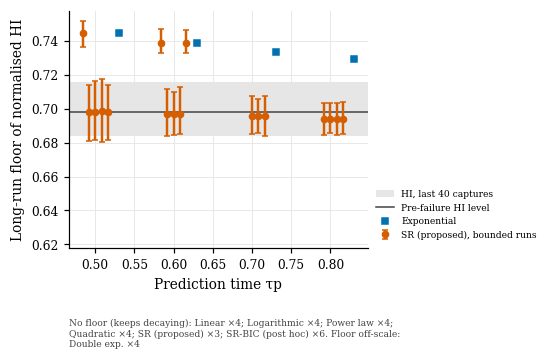

In [46]:
# Figure 6: floor of each law vs prediction time, compared with the pre-failure HI level
fig, ax = plt.subplots(figsize=(3.5, 2.8))
ax.axhspan(*Y_EOL_BAND, color="#e6e6e6", lw=0, label="HI, last 40 captures")
ax.axhline(Y_EOL, color="#444444", lw=1, label="Pre-failure HI level")
sp = FLOOR[(FLOOR.model == "SR (proposed)") & FLOOR.bounded]
jit = {sd: (i - (len(CFG.seeds) - 1) / 2) * 0.008 for i, sd in enumerate(CFG.seeds)}
for i, (_, r_) in enumerate(sp.iterrows()):
    x = r_.tp + jit.get(r_.seed, 0)
    yerr = None
    if "floor_lo" in r_ and np.isfinite(r_.get("floor_lo", np.nan)):
        yerr = [[max(r_.floor - r_.floor_lo, 0)], [max(r_.floor_hi - r_.floor, 0)]]
    ax.errorbar(x, r_.floor, yerr=yerr, fmt="o", ms=4, color=STYLE["SR (proposed)"][0], capsize=2,
                label="SR (proposed), bounded runs" if i == 0 else None, zorder=5)
for m, mk in (("Exponential", "s"), ("Logarithmic", "^")):
    r_ = FLOOR[(FLOOR.model == m) & FLOOR.bounded]
    if r_.empty:
        continue
    ax.plot(r_.tp + 0.03, r_.floor, marker=mk, ls="none", ms=4, color=STYLE[m][0], label=m)
lo_, hi_ = Y_EOL - 0.08, Y_EOL + 0.06
ax.set_ylim(lo_, hi_)
unb = FLOOR[~FLOOR.bounded].groupby("model").size()
out = FLOOR[FLOOR.bounded & ((FLOOR.floor < lo_) | (FLOOR.floor > hi_))].groupby("model").size()
note = []
if len(unb):
    note.append("No floor (keeps decaying): " + "; ".join(f"{k} ×{v}" for k, v in unb.items()))
if len(out):
    note.append("Floor off-scale: " + "; ".join(f"{k} ×{v}" for k, v in out.items()))
import textwrap
if note:
    ax.text(0.0, -0.30, textwrap.fill(". ".join(note), 70), transform=ax.transAxes, fontsize=6, va="top",
            color="#444444")
ax.set_xlabel("Prediction time τp"); ax.set_ylabel("Long-run floor of normalised HI")
ax.legend(frameon=False, fontsize=6, loc="lower left", bbox_to_anchor=(1.0, 0.0))
savefig(fig, "fig6_floor_analysis")

### 15b. (Optional) Threshold-crossing RUL
Disabled by default because it is ill-posed for a saturating HI (see above). Set `CFG.run_threshold_rul = True` to reproduce the α–λ analysis, e.g. with a different HI or more units.

In [47]:
# Optional: threshold-crossing RUL (set CFG.run_threshold_rul = True). Kept for other HIs / more units.
if CFG.run_threshold_rul:
    Y_EOL = float(np.mean(Y[-CFG.rul_threshold_window:]))
    DIR = np.sign(spearmanr(TAU, Y).correlation)
    T_SEARCH = np.linspace(0, CFG.rul_horizon, 6000)

    def crossing(yy, tp):
        m = T_SEARCH >= tp
        hit = (yy[m] <= Y_EOL) if DIR < 0 else (yy[m] >= Y_EOL)
        return float(T_SEARCH[m][np.argmax(hit)]) if hit.any() else np.nan

    RUL_ROWS = []
    for tp in CFG.pred_points:
        rul_true = 1.0 - tp
        for seed in CFG.seeds:
            s = SR_MODELS[(tp, seed, "proposed")]
            eol = crossing(s["expr"](T_SEARCH, s["p"]), tp)
            boot = np.array([crossing(s["expr"](T_SEARCH, pb), tp) for pb in BOOT_PARAMS[(tp, seed)][:200]])
            boot_rul = boot - tp
            RUL_ROWS.append(dict(tp=tp, method="SR (proposed)", seed=seed, rul_true=rul_true, rul_pred=eol - tp,
                                 rul_p05=np.nanpercentile(boot_rul, 5) if np.isfinite(boot_rul).any() else np.nan,
                                 rul_p95=np.nanpercentile(boot_rul, 95) if np.isfinite(boot_rul).any() else np.nan,
                                 censored_frac=float(np.mean(~np.isfinite(boot)))))
        for m in BASELINES:
            fun, p = BL_MODELS[(tp, m)]
            eol = crossing(fun(T_SEARCH, p), tp)
            RUL_ROWS.append(dict(tp=tp, method=m, seed=np.nan, rul_true=rul_true, rul_pred=eol - tp))
        eol = crossing(BL_MODELS[(tp, "GPR")].predict(T_SEARCH[:, None]), tp)
        RUL_ROWS.append(dict(tp=tp, method="GPR", seed=np.nan, rul_true=rul_true, rul_pred=eol - tp))
    RUL = pd.DataFrame(RUL_ROWS)
    RUL["abs_err"] = (RUL.rul_pred - RUL.rul_true).abs()
    RUL["RA"] = 1 - RUL.abs_err / RUL.rul_true
    RUL["in_alpha_cone"] = RUL.abs_err <= CFG.alpha * RUL.rul_true
    RUL["rul_pred_captures"] = RUL.rul_pred * N_LIFE
    RUL.to_csv(OUT / "tables" / "rul_all.csv", index=False)
    T_RUL = (RUL.groupby(["tp", "method"])
               .agg(RUL_true=("rul_true", "first"), RUL_pred=("rul_pred", "mean"), RA=("RA", "mean"),
                    alpha_lambda_hit=("in_alpha_cone", "mean"), censored=("rul_pred", lambda v: np.mean(~np.isfinite(v))))
               .reset_index())
    T_RUL.to_csv(OUT / "tables" / "table_rul.csv", index=False)

    # Threshold sensitivity: the HI flattens near EOL, so RUL is sensitive to how y_EOL is defined
    SENS = []
    for wnd in (5, 10, 20, 40):
        thr = float(np.mean(Y[-wnd:]))
        for tp in CFG.pred_points:
            for seed in CFG.seeds:
                s = SR_MODELS[(tp, seed, "proposed")]
                yy = s["expr"](T_SEARCH, s["p"]); m = T_SEARCH >= tp
                hit = (yy[m] <= thr) if DIR < 0 else (yy[m] >= thr)
                eol = float(T_SEARCH[m][np.argmax(hit)]) if hit.any() else np.nan
                SENS.append(dict(window=wnd, y_eol=thr, tp=tp, seed=seed, RA=1 - abs((eol - tp) - (1 - tp)) / (1 - tp)))
    T_SENS = pd.DataFrame(SENS).groupby(["window", "tp"]).agg(y_eol=("y_eol", "first"), RA_mean=("RA", "mean")).reset_index()
    T_SENS.to_csv(OUT / "tables" / "table_rul_threshold_sensitivity.csv", index=False)
    print("SR relative accuracy vs threshold definition (mean of last n captures):")
    print(T_SENS.pivot(index="window", columns="tp", values="RA_mean").round(3).to_string())
    print(f"EOL threshold (normalised HI) = {Y_EOL:.4f};  1 unit of τ = {N_LIFE} captures")
    T_RUL.round(3)

In [48]:
# Optional: threshold-crossing RUL (set CFG.run_threshold_rul = True). Kept for other HIs / more units.
if CFG.run_threshold_rul:
    # Figure 6: α–λ plot
    fig, ax = plt.subplots(figsize=(3.5, 2.8))
    tt = np.linspace(min(CFG.pred_points) - 0.05, 1, 50)
    ax.plot(tt, 1 - tt, color="#444444", lw=1, label="True RUL")
    ax.fill_between(tt, (1 - CFG.alpha) * (1 - tt), (1 + CFG.alpha) * (1 - tt), color="#bbbbbb", alpha=0.35, lw=0,
                    label=f"α = {CFG.alpha} cone")
    for j, m in enumerate(["SR (proposed)"] + [b for b in BASELINES] + ["GPR"]):
        r = RUL[RUL.method == m].groupby("tp")
        x = np.array(list(r.groups.keys())) + (j - 3.5) * 0.006
        y = r.rul_pred.median().values
        c, ls = STYLE[m]
        if m == "SR (proposed)":
            lo = r.rul_p05.median().values; hi = r.rul_p95.median().values
            ax.errorbar(x, y, yerr=[np.clip(y - lo, 0, None), np.clip(hi - y, 0, None)], fmt="o", color=c, ms=5,
                        capsize=2, label=m, zorder=5)
        else:
            ax.plot(x, y, marker="s" if m != "GPR" else "^", ls="none", color=c, ms=3.5, label=m)
    ax.set_xlabel("Prediction time τp"); ax.set_ylabel("RUL (fraction of life)")
    ax.set_ylim(0, 1.0)
    ax.legend(frameon=False, fontsize=6, ncol=2)
    savefig(fig, "figS1_alpha_lambda")

## 16. (Recommended for publication) Leave-one-unit-out validation with more run-to-failure units
Put extra units in `EXTRA_UNITS` as DataFrames with columns `tau` (0–1, EOL = 1) and `hi` (normalised the same way), for example from your own power-cycling tests. With ≥ 3 units in total the cell trains one SR model on all units but one and tests on the held-out trajectory, for each unit in turn.

In [49]:
EXTRA_UNITS = globals().get("EXTRA_UNITS", {})   # {"unit_name": DataFrame(tau=..., hi=...)}
UNITS = {"A17": pd.DataFrame({"tau": TAU, "hi": Y}), **EXTRA_UNITS}
LOUO = None
if len(UNITS) >= 3:
    rows = []
    for held in UNITS:
        trn = pd.concat([u for n, u in UNITS.items() if n != held])
        tst = UNITS[held]
        errs = []
        for seed in CFG.seeds:
            tag = f"louo_{held}_s{seed}_it{CFG.niterations}"
            order = np.argsort(trn.tau.values)
            t_all, y_all = trn.tau.values[order], trn.hi.values[order]
            rng_ = np.random.default_rng(seed)
            vmask = rng_.random(len(t_all)) < CFG.inner_val_frac     # random split across pooled units
            eqs = run_pysr(t_all[~vmask], y_all[~vmask], seed, tag)
            s = select_equation(eqs, t_all[~vmask], y_all[~vmask], t_all[vmask], y_all[vmask], t_all, y_all,
                                np.sign(spearmanr(t_all, y_all).correlation), True)
            yh = s["expr"](tst.tau.values, s["p"])
            rows.append(dict(held_out=held, seed=seed, form=s["expr"].form, test_rmse=rmse(tst.hi.values, yh)))
    LOUO = pd.DataFrame(rows)
    LOUO.to_csv(OUT / "tables" / "table_louo.csv", index=False)
    display(LOUO.groupby("held_out").test_rmse.agg(["mean", "std"]))
else:
    print(f"Only {len(UNITS)} unit(s) available; leave-one-unit-out skipped (needs ≥ 3).")

Only 1 unit(s) available; leave-one-unit-out skipped (needs ≥ 3).


## 17. Export: LaTeX tables, environment and an auto-drafted methods paragraph

In [50]:
def to_latex(df, path, caption, label):
    cols = list(df.columns)
    esc = lambda s: str(s).replace("_", r"\_").replace("%", r"\%").replace("τ", r"$\tau$").replace("±", r"$\pm$")
    lines = [r"\begin{table}[t]", r"\centering", rf"\caption{{{caption}}}", rf"\label{{{label}}}",
             r"\begin{tabular}{" + "l" * len(cols) + "}", r"\hline", " & ".join(esc(c) for c in cols) + r" \\", r"\hline"]
    for _, r_ in df.iterrows():
        lines.append(" & ".join(esc(f"{v:.4g}" if isinstance(v, float) else v) for v in r_.values) + r" \\")
    lines += [r"\hline", r"\end{tabular}", r"\end{table}"]
    Path(path).write_text("\n".join(lines))

to_latex(HI_TAB.round(3).reset_index().rename(columns={"index": "HI"}), OUT / "tables" / "hi_selection.tex",
         "Health-indicator suitability metrics (A17, aging regime).", "tab:hi")
to_latex(T_MAIN, OUT / "tables" / "main_results.tex", "Extrapolation error on the test window.", "tab:main")
to_latex(ABL.round(4), OUT / "tables" / "ablation.tex", "Ablation of model-selection choices.", "tab:ablation")
to_latex(T_UQ.round(3), OUT / "tables" / "uncertainty.tex", "Prediction-interval quality (95 %).", "tab:uq")
to_latex(T_IC.round(4), OUT / "tables" / "information_criteria.tex", "Training-window BIC and test RMSE.", "tab:ic")
to_latex(FAM_TAB.round(4), OUT / "tables" / "family_stability.tex", "Functional families of the selected equations.", "tab:families")
to_latex(T_FLOOR.round(4), OUT / "tables" / "floor_analysis.tex", "Long-run floor of each law vs. the pre-failure HI level.", "tab:floor")
if CFG.run_threshold_rul:
    to_latex(T_RUL.round(3), OUT / "tables" / "rul.tex", "RUL accuracy.", "tab:rul")

try:
    from juliacall import Main as jl
    julia_version = str(jl.seval("string(VERSION)"))
    sr_jl_version = str(jl.seval("string(pkgversion(SymbolicRegression))"))
except Exception:
    julia_version = sr_jl_version = "n/a"
ENV = dict(python=platform.python_version(), pysr=getattr(pysr, "__version__", "?"), julia=julia_version,
           SymbolicRegression_jl=sr_jl_version, numpy=np.__version__, scipy=scipy.__version__,
           sklearn=sklearn.__version__, pandas=pd.__version__, matplotlib=matplotlib.__version__,
           platform=platform.platform(), data_sha256=digest)
json.dump(ENV, open(OUT / "environment.json", "w"), indent=2)

dom = GLOBAL_FAMILIES.index[0]
n_dom = int(GLOBAL_FAMILIES.iloc[0]["n_runs"])
bic_fams = bicv.family.value_counts()
fl_dom = FLOOR[(FLOOR.model == "SR (proposed)") & (FLOOR.family == dom) & FLOOR.bounded]
ic_best = T_IC.sort_values("BIC").groupby("tp").first().model.value_counts()
methods_txt = f"""Health indicator. {len(FEAT)} switching transients of NASA PCoE IGBT device A17 (1 ns sampling) were processed; \
{K0 - FEAT.index.min()} burn-in captures (gate-duty-cycle adjustment) were removed by an objective regime rule, leaving {len(D)} captures. \
Six candidate indicators were ranked by monotonicity, trendability and robustness; {HI_NAME} scored highest \
(composite {HI_TAB.loc[HI_NAME, 'composite']:.3f}) and was normalised to its first {CFG.norm_n} values.
Symbolic regression. PySR {ENV['pysr']} (SymbolicRegression.jl {sr_jl_version}, Julia {julia_version}) searched expressions built from \
{{{', '.join(CFG.binary_operators)}}} and {{{', '.join(CFG.unary_operators)}}} with maximum size {CFG.maxsize}, {CFG.populations} populations of \
{CFG.population_size} individuals and {CFG.niterations} iterations, in deterministic serial mode, with {len(CFG.seeds)} random seeds.
Evaluation. For prediction points τp ∈ {list(CFG.pred_points)} only data with τ ≤ τp were used. The last {int(CFG.inner_val_frac * 100)} % of that \
window served as validation for choosing an equation from the Pareto front: the simplest physics-admissible equation (finite, bounded and \
monotone on τ ∈ [0, {CFG.admissible_grid_max}]) within {int(CFG.tie_tolerance * 100)} % of the best validation RMSE. Its constants were then refitted \
on the full training window. Baselines (linear, quadratic, exponential, power-law, logarithmic, double-exponential, Gaussian process) used \
the same windows. Prediction intervals came from a moving-block residual bootstrap (B = {CFG.n_bootstrap}). Selected equations were grouped \
into functional families by numerical equivalence of their curves (tolerance {CFG.family_tol:g} of the curve range). As a post-hoc secondary \
analysis, equations were also selected by minimum BIC on the training window. Because the HI saturates, threshold-based RUL was replaced \
by an analysis of each law's long-run floor relative to the pre-failure HI level (y_EOL = {Y_EOL:.4f}).
Main results. The pre-registered rule selected the {dom} family in {n_dom} of {len(prop)} runs \
(median test RMSE {GLOBAL_FAMILIES.iloc[0]['median_test_rmse']:.4f}). Under BIC selection the most common family was \
{bic_fams.index[0] if len(bic_fams) else 'n/a'} ({int(bic_fams.iloc[0]) if len(bic_fams) else 0} of {len(bicv)} runs). The lowest-BIC model per \
prediction point was: {', '.join(f'{k} ({v}x)' for k, v in ic_best.items())}. For bounded runs of the {dom} family the median floor was \
{fl_dom.floor.median():.4f} versus y_EOL = {Y_EOL:.4f}, with {fl_dom.completed_at_eol.median() * 100:.1f} % of the eventual decay completed at failure.
"""
(OUT / "methods_draft.txt").write_text(methods_txt)
print(methods_txt)
print(json.dumps(ENV, indent=1))
shutil.make_archive(str(OUT), "zip", OUT)
print("All results zipped to", str(OUT) + ".zip")
if IN_COLAB:
    from google.colab import files
    files.download(str(OUT) + ".zip")

Health indicator. 418 switching transients of NASA PCoE IGBT device A17 (1 ns sampling) were processed; 15 burn-in captures (gate-duty-cycle adjustment) were removed by an objective regime rule, leaving 403 captures. Six candidate indicators were ranked by monotonicity, trendability and robustness; os_area_norm scored highest (composite 0.680) and was normalised to its first 10 values.
Symbolic regression. PySR 1.5.9 (SymbolicRegression.jl 1.11.3, Julia 1.11.9) searched expressions built from {+, -, *, /} and {exp, log, sqrt} with maximum size 20, 15 populations of 33 individuals and 300 iterations, in deterministic serial mode, with 5 random seeds.
Evaluation. For prediction points τp ∈ [0.5, 0.6, 0.7, 0.8] only data with τ ≤ τp were used. The last 15 % of that window served as validation for choosing an equation from the Pareto front: the simplest physics-admissible equation (finite, bounded and monotone on τ ∈ [0, 1.5]) within 5 % of the best validation RMSE. Its constants were then

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 18. Limitations to state in the paper, and a reporting checklist
**Limitations (be explicit about them; reviewers will raise them anyway)**
1. **Single run-to-failure unit** with transients (A17). Claims are about within-unit extrapolation. Add units and use Section 16 to claim generalisation.
2. **Aging clock** = capture index (timestamps not stored); assumes a constant capture rate.
3. **Saturating HI.** The turn-off overshoot levels off before latch-up, so it does not by itself predict the failure time. Threshold RUL is disabled; report the floor analysis (`table_floor_analysis.csv`) instead.
3b. **Selection rule vs. information criteria.** The pre-registered rule favours the simplest adequate law (hyperbolic, 3 constants); BIC favours 4-constant laws. Report both, and label the BIC variant as post hoc.
3c. **Conservative intervals.** Bootstrap PI coverage above the 95 % target means the intervals are wider than needed; say so next to `table_uncertainty.csv`.
4b. **Early fast decay** (τ < 0.1) may partly be thermal settling rather than aging. Re-run with `extra_burnin = 20` and report whether the discovered form changes.
4. **Accelerated thermal overstress** (package ≈ 330 in controller units, well beyond the rating) differs from field power cycling. The discovered law describes this stress mode.
5. **8-bit oscilloscope quantisation** (0.0625 V steps). Averaged features reduce but do not remove it.

**Checklist before submission**
- [ ] Report the PySR/Julia versions from `environment.json` and the full `config.json`
- [ ] Include `table_family_stability.csv` and `table_dominant_family_constants.csv`: how often the law was found and how stable its constants are
- [ ] Include `table_information_criteria.csv` (BIC) next to the test-error table
- [ ] Report mean ± s.d. over seeds, not the best seed
- [ ] Show the ablation table (physics filter, selection rule)
- [ ] Give a physical interpretation of the law (e.g. overshoot ∝ di/dt ∝ turn-off speed, which changes with latch-up precursors / tail current)
- [ ] Share code and the SHA-256 of the data file
- [ ] Cite: Celaya, Wysocki & Goebel (2009) data set; Sonnenfeld, Goebel & Celaya (2008) Autotestcon; Cranmer (2023) PySR arXiv:2305.01582; Coble & Hines (2009) PHM Society; Saxena et al. (2008) prognostics metrics